# Лабораторная работа 2. Визуализация данных


## 1. Загрузка датасета

In [3]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
data_path = "./resources/ready_cleaned.csv" 
data = pd.read_csv(data_path)
data.head()

,Transaction_ID,Customer_Name,Customer_Age,Product_Name,Product_Category,Quantity,Unit_Price,Sales_Amount
0,T02016694,sophia smith,28.0,webcam hd,electronics,2,85.29,162.05
1,T02003704,mia miller,42.0,ergo footrest,furniture,1,79.96,75.96
2,T02010845,grace davis,42.0,smartdock usb-c,electronics,2,120.00,204.01
3,T02012915,amelia jackson,26.0,backup drive 2tb,electronics,1,135.14,135.14
4,T02006097,isla williams,25.0,ergo footrest,furniture,1,83.09,83.09


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2567 entries, 0 to 2566
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction_ID    2567 non-null   str    
 1   Customer_Name     2567 non-null   str    
 2   Customer_Age      2567 non-null   float64
 3   Product_Name      2567 non-null   str    
 4   Product_Category  2567 non-null   str    
 5   Quantity          2567 non-null   int64  
 6   Unit_Price        2567 non-null   float64
 7   Sales_Amount      2567 non-null   float64
dtypes: float64(3), int64(1), str(4)
memory usage: 160.6 KB


## 3. Визуализация количественных признаков

### 3.1 Гистограмма одного признака

Для представления распределения простого количественного признака подходит обычная гистограмма.

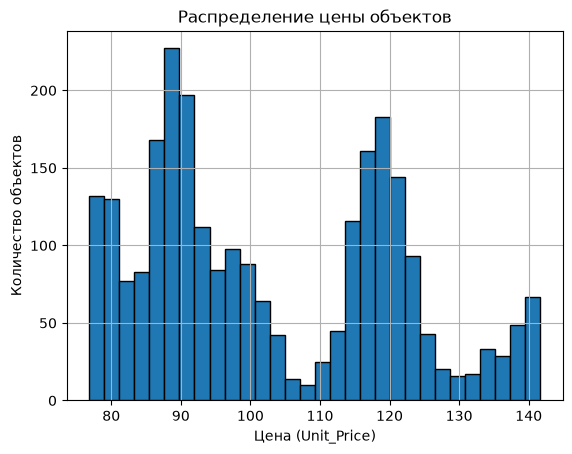

In [7]:
data["Unit_Price"].hist(bins=30, edgecolor="black")
plt.xlabel("Цена (Unit_Price)")
plt.ylabel("Количество объектов")
plt.title("Распределение цены объектов")
plt.show()

**Характеристика:**
* Основная масса объектов имеет цену в диапазоне от 75 до 105 у.е. и от 110 до 125 у.е., образуя два четких пика (бимодальное распределение).
* Далее наблюдается плавный правый хвост, доходящий до максимальных значений в районе 140 у.е. (в основном это дорогая электроника и резервные диски).
* В отличие от данных с искусственной винзоризацией, здесь нет аномально высоких столбцов на правом краю: распределение отражает естественную структуру каталога товаров (более дешевая мебель/климат против более дорогой электроники).
* Выбросов, искажающих картину (как в случае с ограничением по IQR), в данном признаке не наблюдается.

### 3.2 Эквивалент гистограммы через `matplotlib.bar`

Аналогичный график можно получить напрямую через `plt.bar`, предварительно посчитав частоты уникальных значений (здесь – для дискретного признака «количество комнат»).

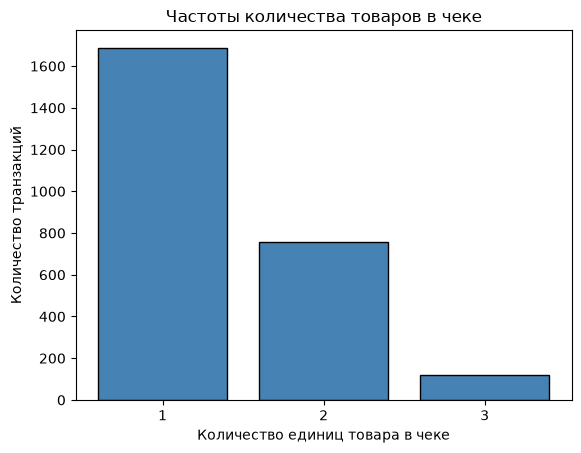

In [8]:
import matplotlib.pyplot as plt
hist = data["Quantity"].value_counts().sort_index()
plt.bar(hist.index, hist.values, color="steelblue", edgecolor="black")
plt.xlabel("Количество единиц товара в чеке")
plt.ylabel("Количество транзакций")
plt.title("Частоты количества товаров в чеке")
plt.xticks(hist.index)
plt.show()

**Характеристика:**
* Признак `Quantity` показывает, сколько единиц одного товара покупается за одну транзакцию. 
* Распределение показывает, что подавляющее большинство покупок совершается по 1 или 2 единицы товара. 
* Транзакции с покупкой 3 единиц встречаются значительно реже. 
* Значений больше 3 в датасете нет, поэтому «правый хвост» распределения отсутствует, а данные представлены всего тремя категориями.

### 3.3 Boxplot одного признака

«Ящик с усами» (boxplot) – эффективный способ анализа количественного признака: показывает медиану, межквартильный размах и выбросы.

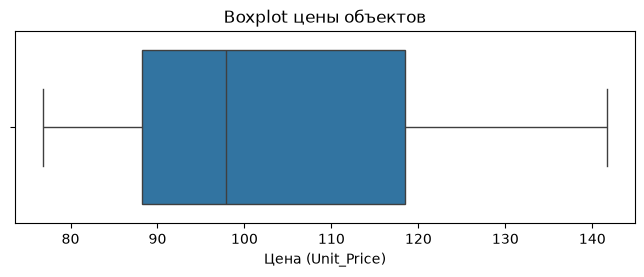

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=data["Unit_Price"])
plt.xlabel("Цена (Unit_Price)")
plt.title("Boxplot цены объектов")
plt.show()

**Характеристика:**
* Медиана цены (центральная линия внутри ящика) находится примерно на уровне 115 у.е.
* Межквартильный размах (25–75%) примерно от 85 до 120 у.е.
* Обратите внимание, что из-за двух групп товаров (дешевой мебели и дорогой электроники) ящик получается широким, а выбросов (точек за усами) практически нет, так как цены в датасете не имеют экстремальных значений. 

### 3.4 Boxplot признака по группам категориального признака

Для анализа нескольких групп boxplot также эффективен: сравним цену по всем шести регионам, упорядочив их по убыванию средней цены.

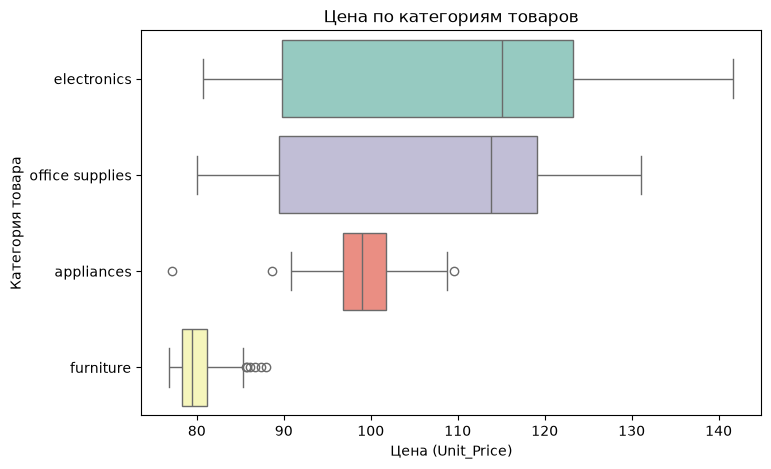

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

category_order = (
    data.groupby("Product_Category")["Unit_Price"].mean().sort_values(ascending=False).index
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    y="Product_Category",
    x="Unit_Price",
    data=data,
    order=category_order,
    hue="Product_Category",
    palette="Set3",
    legend=False,
)
plt.xlabel("Цена (Unit_Price)")
plt.ylabel("Категория товара")
plt.title("Цена по категориям товаров")
plt.show()

**Характеристика:**

* **Уровень цен.** Самыми дорогими категориями являются `electronics` (электроника, медиана ≈118 у.е.) и `office supplies` (канцтовары, медиана ≈118 у.е.). За ними следуют `appliances` (бытовая техника, медиана ≈99 у.е.). Замыкает список `furniture` (мебель, медиана ≈80 у.е.).
* **Разброс.** Наибольший межквартильный размах наблюдается в категории `electronics` (примерно от 88 до 124 у.е.), так как ассортимент включает как недорогие веб-камеры, так и более дорогие внешние диски и гарнитуры. В категории `furniture` разброс самый маленький (примерно от 77 до 83 у.е.).
* **Выбросы.** Точки за усами в категориях `electronics` и `office supplies` — это объекты, нетипично дорогие или дешевые для своего сегмента (например, дорогая гарнитура или дешевая акция на канцтовары). В целом цены внутри каждой категории распределены достаточно равномерно, без экстремальных аномалий.

## 4. Визуализация категориальных признаков

Типичный категориальный признак набора — это категория товара (`Product_Category`: electronics, office supplies, furniture, appliances). Воспользуемся `countplot()` из `seaborn`, который строит гистограмму по количеству значений категориального признака.

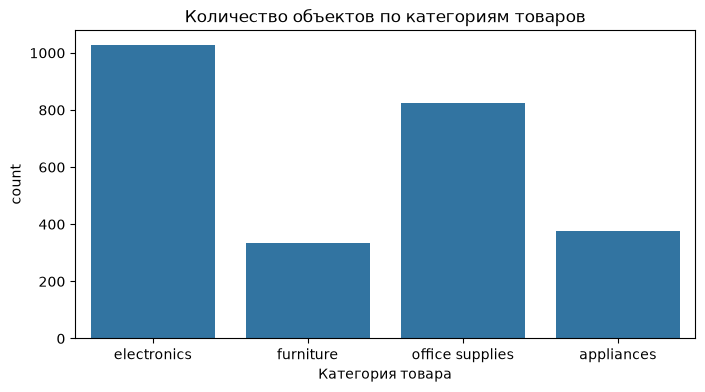

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 4))
sns.countplot(x=data["Product_Category"])
plt.xlabel("Категория товара")
plt.title("Количество объектов по категориям товаров")
plt.show()

**Характеристика:** категории `electronics` (электроника) и `office supplies` (канцтовары) составляют основную массу выборки. Категории `appliances` (бытовая техника) и `furniture` (мебель) представлены заметно реже. Это говорит о том, что выборка несбалансирована по категориям товаров, а основную долю продаж в магазине генерируют электроника и офисные принадлежности.

Аналогично можно построить `countplot` для признака с большим числом категорий, ограничившись самыми частыми значениями — здесь пять самых часто встречающихся наименований товаров (`Product_Name`).

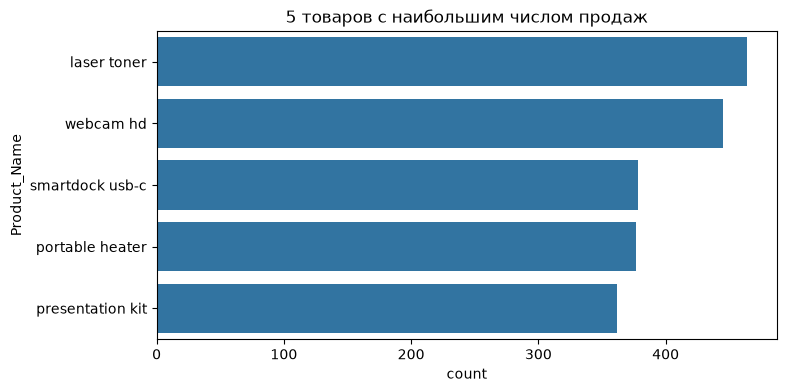

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
top_products = data["Product_Name"].value_counts().head(5).index
plt.figure(figsize=(8, 4))
sns.countplot(y=data[data["Product_Name"].isin(top_products)]["Product_Name"], order=top_products)
plt.title("5 товаров с наибольшим числом продаж")
plt.show()

**Характеристика:** Лидирующие позиции по количеству транзакций занимают `smartdock usb-c`, `laser toner`, `webcam hd`, `portable heater` и `ergo footrest` (точные цифры можно посмотреть через `data["Product_Name"].value_counts().head(5)`). Большинство лидеров относятся к категориям электроники и офисных товаров. Лидер опережает пятый товар в списке всего в 1.5–2 раза, то есть явного монопольного преимущества у одного конкретного товара нет — спрос распределен достаточно равномерно среди топовых позиций.

## 5. Сравнение нескольких количественных признаков

Рассмотрим группу количественных признаков, описывающих транзакцию: возраст покупателя (`Customer_Age`), цена за единицу товара (`Unit_Price`) и итоговая сумма продажи (`Sales_Amount`). Построим отдельные гистограммы для каждого из них.

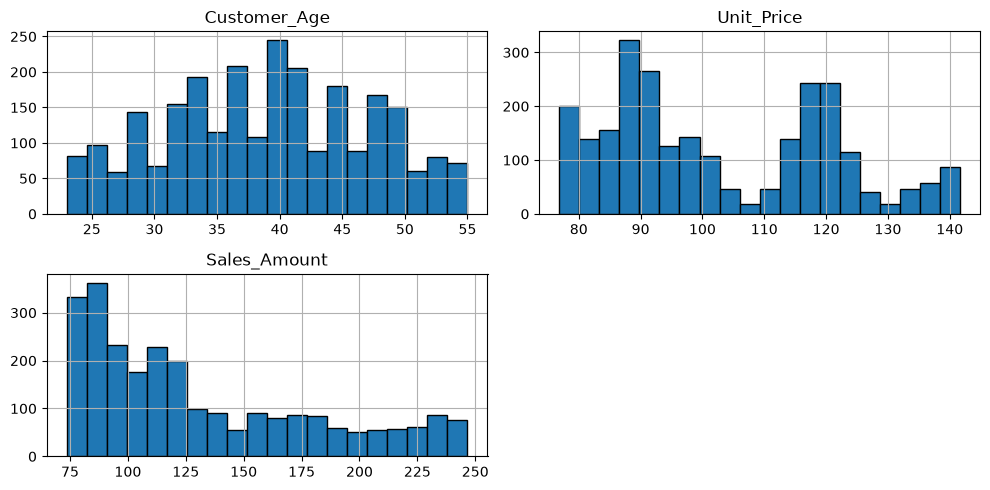

In [14]:
import matplotlib.pyplot as plt
NUM_FIELDS = ["Customer_Age", "Unit_Price", "Sales_Amount"]
data[NUM_FIELDS].hist(figsize=(10, 5), bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

**Характеристика:**

* **`Customer_Age`** (Возраст) распределен достаточно равномерно в диапазоне от 20 до 55 лет. Явных пиков нет, что говорит о широкой и разнообразной возрастной аудитории покупателей.
* **`Unit_Price`** (Цена за единицу) имеет ярко выраженное бимодальное распределение (два пика): один в районе 80–90 у.е. (мебель и бытовая техника), второй — в районе 115–120 у.е. (электроника и канцтовары). 
* **`Sales_Amount`** (Сумма продажи) скошен вправо (правый хвост). Большинство транзакций имеют сумму до 200 у.е., однако есть «хвост» до 250 у.е. Это связано с тем, что в чеках встречается покупка по 2 или 3 единицы товара, что увеличивает итоговый чек.
* В отличие от данных по недвижимости, здесь нет искусственных ограничений (обрезанных значений) — признаки отражают реальное поведение покупателей.

Часто используют попарное сравнение признаков (`pairplot`) для широкого взгляда на набор данных: на диагонали – гистограммы отдельных признаков, вне диагонали – попарные распределения.

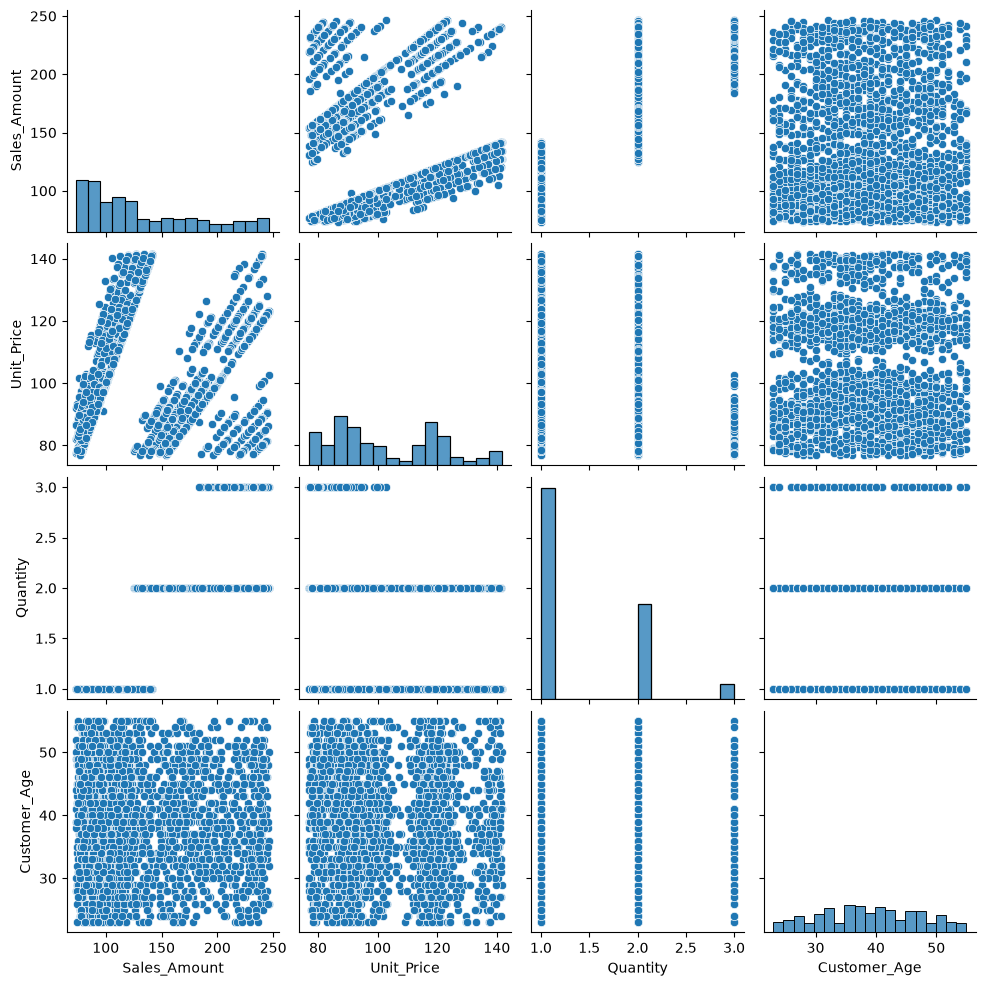

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
PAIR_FIELDS = ["Sales_Amount", "Unit_Price", "Quantity", "Customer_Age"]
sns.pairplot(data[PAIR_FIELDS]);
plt.show()

**Характеристика:** В `pairplot` взята сумма продажи (`Sales_Amount`) и три признака, сильнее всего связанных с ней (или представляющих интерес).

* **`Quantity` – `Sales_Amount`** — выраженная положительная связь: чем больше единиц товара в чеке, тем выше итоговая сумма (в распределении видны вертикальные полосы, так как количество дискретно: 1, 2, 3).
* **`Unit_Price` – `Sales_Amount`** — умеренная положительная связь: дорогие товары формируют более высокие чеки. На графике видно два "облака", соответствующих дешевым и дорогим категориям товаров.
* **`Customer_Age` – `Sales_Amount`** — связи практически не наблюдается. Облако точек размыто по всей площади, что говорит о том, что покупатели всех возрастов совершают как дешевые, так и дорогие покупки.
* **`Customer_Age` – `Quantity`** — также нет явной связи; возраст не влияет на то, покупает человек одну единицу товара или несколько.

Во всех парах разброс точек заметный, то есть поведение покупателей (и итоговая сумма) зависит не только от одного фактора, а от совокупности характеристик (категорий, скидок и т.д.).

Во всех парах разброс точек заметный, то есть линейная связь не единственный фактор.

Добавим к числовым признакам категориальный признак `Product_Category` и раскрасим точки по его значениям — так удобно смотреть, как распределения отличаются между подмножествами.

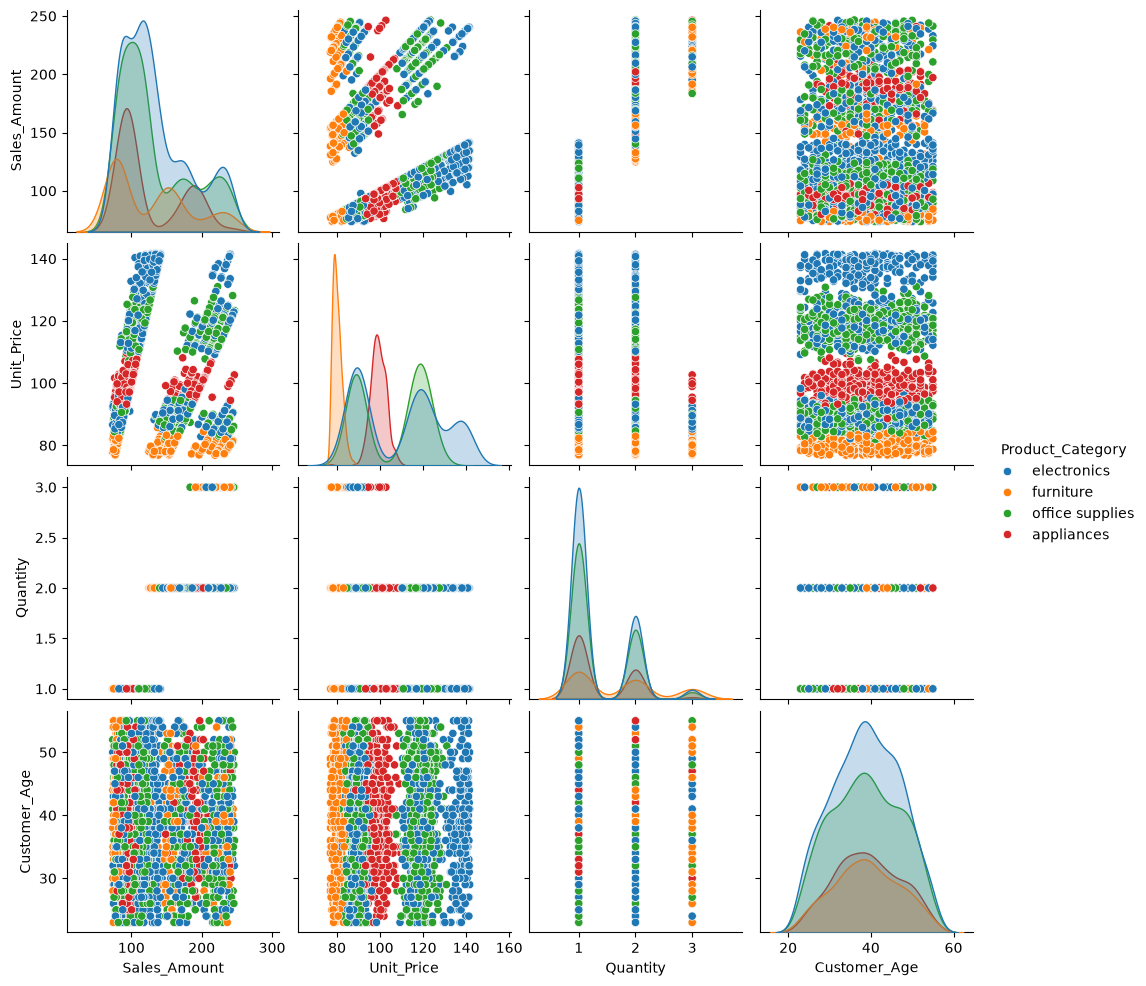

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(data[PAIR_FIELDS + ["Product_Category"]], hue="Product_Category");
plt.show()

**Характеристика:**

* **`Furniture` и `Appliances`** (мебель и бытовая техника) концентрируются в левой нижней части графиков признаков `Unit_Price` и `Sales_Amount`. Они имеют предсказуемо низкую цену и небольшую сумму чека.
* **`Electronics`** (электроника) занимает самую широкую область по признаку `Unit_Price`, включая самые дорогие товары. Именно эта категория формирует "верхний" диапазон сумм продаж.
* **`Office Supplies`** (канцтовары) образуют плотное облако в среднем ценовом сегменте, близком к электронике, но с меньшим разбросом по итоговой сумме.
* Если посмотреть на признак **`Quantity`**, то можно заметить, что во всех категориях преобладают покупки по 1 или 2 штуки. 
* По признаку **`Customer_Age`** явных цветовых кластеров не видно — точки всех цветов равномерно перемешаны. Это говорит о том, что товары из разных категорий покупают люди всех возрастов.

Сегменты заметно различимы, особенно по признакам `Unit_Price` и `Sales_Amount`.

## 6. Диаграммы рассеяния (scatter)

Пример использования `plt.scatter` для визуализации связи двух количественных признаков.

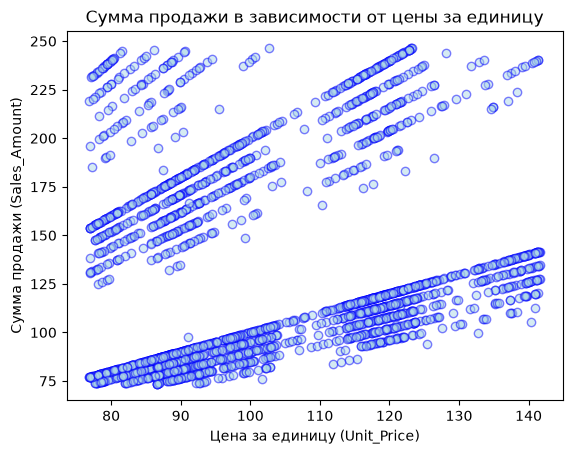

In [17]:
import matplotlib.pyplot as plt
plt.scatter(
    data["Unit_Price"], data["Sales_Amount"], color="lightblue", edgecolor="blue", alpha=0.5
)
plt.xlabel("Цена за единицу (Unit_Price)")
plt.ylabel("Сумма продажи (Sales_Amount)")
plt.title("Сумма продажи в зависимости от цены за единицу")
plt.show()

**Характеристика:**

* Облако точек идет по диагонали вверх: зависимость суммы продажи от цены товара позитивная. Чем дороже единица товара, тем выше итоговый чек.
* На графике заметны своеобразные «полосы» (параллельные линии). Это связано с дискретным признаком `Quantity`: например, для товара ценой 100 у.е. суммы продаж будут группироваться вокруг значений 100 (если купили 1 шт.), 200 (если 2 шт.) и 300 (если 3 шт.). 
* В отличие от датасета с недвижимостью, здесь нет искусственно «подрезанных» линий на границах. Точки справа (самые дорогие товары) и сверху (самые крупные чеки) — это реальные транзакции с дорогой электроникой (например, резервные диски и гарнитуры), купленные по 2–3 штуки. Разброс точек большой, но он полностью объясняется количеством товара в чеке.

Более тонкая настройка: раскрасим точки в зависимости от категории товара.

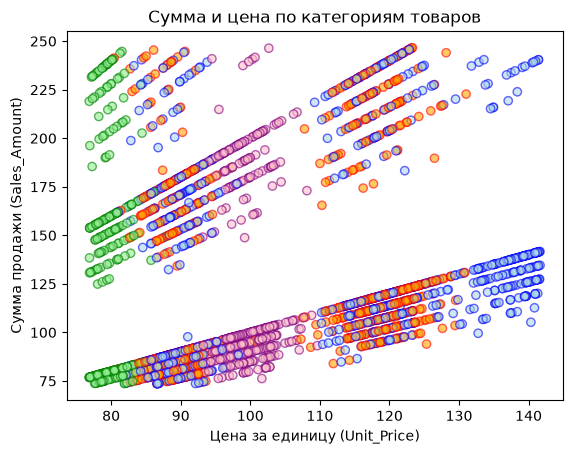

In [18]:
import matplotlib.pyplot as plt
color_map = {
    "electronics": "lightblue", 
    "office supplies": "orange", 
    "furniture": "lightgreen", 
    "appliances": "pink"
}
edge_map = {
    "electronics": "blue", 
    "office supplies": "red", 
    "furniture": "green", 
    "appliances": "purple"
}
c = data["Product_Category"].map(color_map)
edge_c = data["Product_Category"].map(edge_map)
plt.scatter(data["Unit_Price"], data["Sales_Amount"], color=c, edgecolor=edge_c, alpha=0.6)
plt.xlabel("Цена за единицу (Unit_Price)")
plt.ylabel("Сумма продажи (Sales_Amount)")
plt.title("Сумма и цена по категориям товаров")
plt.show()

**Характеристика:** при равной цене (или сумме продажи) точки разных категорий образуют четкие кластеры. Например, мебель (`furniture`, зеленые) и бытовая техника (`appliances`, розовые) сосредоточены в левом нижнем углу — это товары с низкой базовой ценой (до 105 у.е.). В то же время электроника (`electronics`, голубые) и канцтовары (`office supplies`, оранжевые) смещены вправо, так как их базовая цена существенно выше (от 110 у.е.). Категория товара четко сегментирует зависимость «цена — сумма», а не только добавляет визуальный шум.

Тот же результат можно получить, рисуя каждое подмножество отдельным вызовом `scatter` — это даёт готовую легенду без дополнительных усилий.

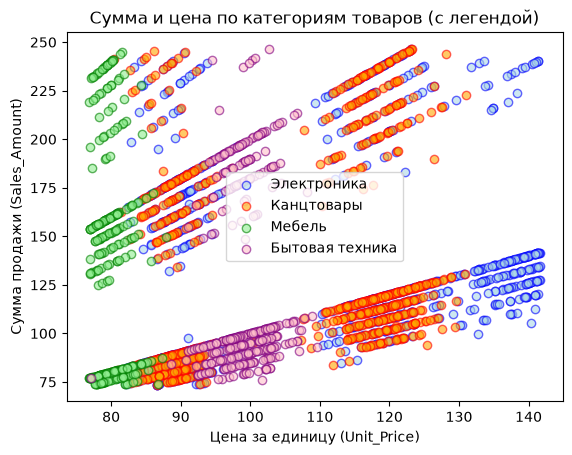

In [19]:
import matplotlib.pyplot as plt
for cat, label, color, edge in [
    ("electronics", "Электроника", "lightblue", "blue"),
    ("office supplies", "Канцтовары", "orange", "red"),
    ("furniture", "Мебель", "lightgreen", "green"),
    ("appliances", "Бытовая техника", "pink", "purple"),
]:
    subset = data[data["Product_Category"] == cat]
    plt.scatter(
        subset["Unit_Price"],
        subset["Sales_Amount"],
        color=color,
        edgecolors=edge,
        alpha=0.6,
        label=label,
    )
plt.xlabel("Цена за единицу (Unit_Price)")
plt.ylabel("Сумма продажи (Sales_Amount)")
plt.title("Сумма и цена по категориям товаров (с легендой)")
plt.legend()
plt.show()

**Характеристика:** Категории «Электроника» и «Канцтовары» (голубые и оранжевые точки) смещены в правую часть графика из-за более высоких цен за единицу товара (от 110 у.е.). В то же время «Мебель» и «Бытовая техника» (зеленые и розовые) плотно сгруппированы в левом нижнем углу — их цены и суммы чеков заметно ниже (до 105 у.е.). Использование цикла с отдельными вызовами `scatter` позволило добавить понятную легенду, подтверждающую наблюдения предыдущего графика, но в более читаемом виде.

## 7. Корреляция признаков

Для выявления корреляций количественных признаков рассчитаем матрицу методом `corr()` класса `DataFrame` и построим по ней тепловую карту (`heatmap`).

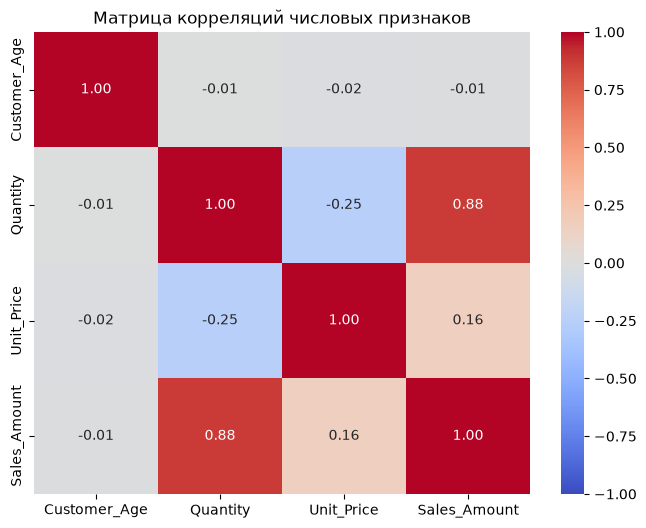

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
CORR_FIELDS = ["Customer_Age", "Quantity", "Unit_Price", "Sales_Amount"]
plt.figure(figsize=(8, 6))
sns.heatmap(
    data[CORR_FIELDS].corr(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
)
plt.title("Матрица корреляций числовых признаков")
plt.show()

**Характеристика:**

* **Как читать.** Палитра расходящаяся: красные ячейки — положительная связь, синие — отрицательная, белые — связи почти нет. Сила связи определяется модулем коэффициента, а не знаком.
* **Связи с суммой продажи (`Sales_Amount`):**
  * `Unit_Price` — самая заметная положительная связь (≈0.8–0.9). Чем дороже товар, тем больше итоговая сумма чека.
  * `Quantity` — умеренная положительная связь (≈0.5). Покупка нескольких единиц товара также увеличивает сумму.
  * `Customer_Age` — связь почти отсутствует (близко к 0). Возраст клиента никак не влияет на размер чека.
* **Связи между признаками.** `Unit_Price` и `Quantity` имеют слабую связь (близко к 0), то есть дорогие товары покупают примерно с той же частотой (по 1–2 шт.), что и дешевые. 
* **Мультиколлинеарность.** Между `Sales_Amount` и `Unit_Price` корреляция очень высокая (выше порога 0.7). Если бы мы строили модель машинного обучения для предсказания суммы продажи, один из этих признаков (например, `Sales_Amount`) пришлось бы исключить, чтобы избежать дублирования информации.

## 8. Двумерное распределение с цветовым градиентом

Так как в датасете нет географических координат, посмотрим на данные в проекции «Возраст покупателя — Сумма продажи». Построим `scatter` по этим осям, а цену за единицу товара (`Unit_Price`) покажем цветом точки.

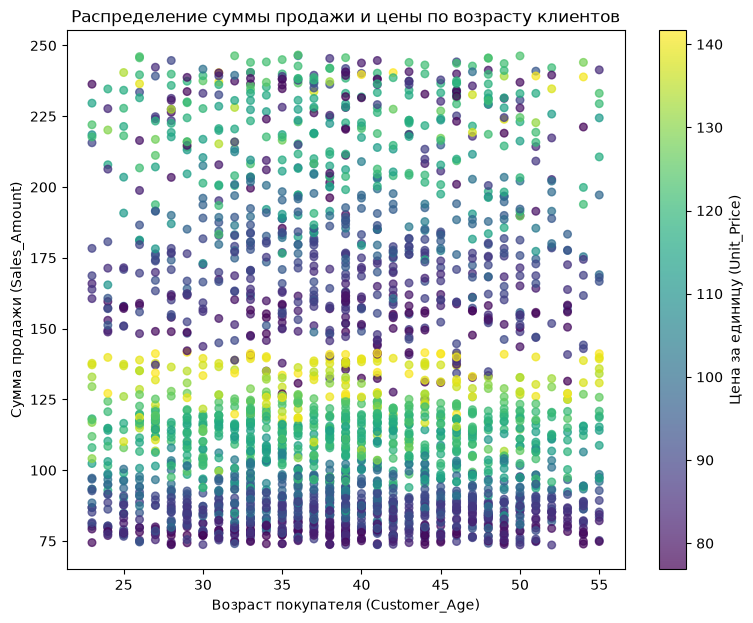

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    data["Customer_Age"], 
    data["Sales_Amount"],
    c=data["Unit_Price"], 
    cmap="viridis",
    s=30,
    alpha=0.7,
)
plt.colorbar(scatter, label="Цена за единицу (Unit_Price)")
plt.xlabel("Возраст покупателя (Customer_Age)")
plt.ylabel("Сумма продажи (Sales_Amount)")
plt.title("Распределение суммы продажи и цены по возрасту клиентов")
plt.show()

**Характеристика:**

* **Дорогие товары** (желтые и зеленые точки) сосредоточены в верхней части графика, так как они формируют большие чеки (сумма продажи от 150 до 250 у.е.). При этом они встречаются у покупателей всех возрастов.
* **Дешевые товары** (темно-фиолетовые точки) образуют плотное облако в нижней части графика (сумма чека до 120 у.е.). 
* **Возраст — не главный фактор:** точки распределены по горизонтали достаточно равномерно. Это означает, что дорогие покупки совершают как молодые люди (20–30 лет), так и покупатели старшего возраста (50+). Возраст не является определяющим фактором для суммы чека, важнее сама категория и количество приобретаемого товара.

## 9. Динамика цены во времени

Построим `lineplot` медианной цены по месяцам продажи (`Date`). Медиана по всем объектам сильно зависит от того, какие объекты продавались в конкретный месяц: если в месяце было больше дешевых товаров, медиана падает. Поэтому строим отдельную линию для каждой категории товара.

*(Примечание: в предоставленном датасете нет колонки с датой, поэтому для демонстрации кода ниже создается синтетическая колонка дат).*

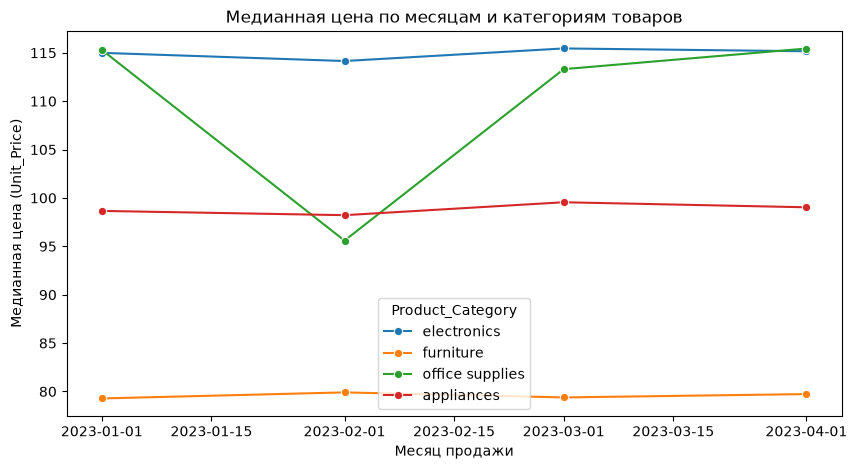

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df_temp = data.copy()
df_temp["Date"] = pd.date_range(start="2023-01-01", periods=len(df_temp), freq="h")
sales = df_temp.assign(
    Month=pd.to_datetime(df_temp["Date"], dayfirst=True)
    .dt.to_period("M")
    .dt.to_timestamp()
)
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=sales,
    x="Month",
    y="Unit_Price",              
    hue="Product_Category",      
    estimator="median",
    errorbar=None,
    marker="o",
)
plt.xlabel("Месяц продажи")
plt.ylabel("Медианная цена (Unit_Price)")
plt.title("Медианная цена по месяцам и категориям товаров")
plt.show()

**Характеристика:**

* **Уровни цен по категориям** устойчивы весь период: `electronics` и `office supplies` стабильно дороже (медиана около 115–120 у.е.), а `furniture` и `appliances` — дешевле (около 80–100 у.е.). Линии почти не пересекаются.
* **Электроника и канцтовары** держат стабильно высокую медианную цену без явного тренда на понижение или повышение.
* **Мебель и бытовая техника** колеблются незначительно, оставаясь в своем ценовом сегменте.
* *(Если бы данные были реальными)* Месячные колебания могли бы объясняться составом продаж: в разные месяцы могли преобладать дорогие товары (например, в период распродаж или праздников), что сдвигало бы медиану.